# Drift-diffusion models of the answer choice

**What a drift-diffusion model is.** It describes a decision as evidence building up over
time. While the participant reads, a running total moves towards one option or another, with
noise, until it reaches a threshold; the option it reaches is the choice, and the moment it
reaches it is the response time. Three things set how this goes:

* **drift rate** -- how fast the evidence builds up: high when the answer is easy to see;
* **boundary** (threshold) -- how much evidence the participant waits for: a cautious
  participant waits longer and makes fewer errors;
* **non-decision time** -- time spent on anything that is not deciding, such as reading and
  pressing the button.

The appeal is that one mechanism explains choices and response times together: a hard
question means slow drift, which means both more errors and slower answers.

**The attentional version (aDDM).** Krajbich and colleagues added the eyes: an option builds
up evidence faster while it is being looked at. That predicts specific links between gaze and
choice -- the option looked at more, and looked at last, tends to be chosen -- and the papers
test the model by whether it reproduces them.

**This notebook goes from no model to models that use the eyes:**

1. The decision and the gaze before it.
2. Decision times.
3. to 7. The gaze-and-choice patterns the aDDM papers look for, with no model.
8. EZ-diffusion: the simplest drift-diffusion model -- right against wrong, no eyes.
9. GLAM: a race between the four answers in which gaze scales each answer's evidence.

**One caveat runs through all of it.** The same gaze-choice patterns arise if people look at an
answer *because* they have already decided on it (Zylberberg, Krajbich & Shadlen 2026). The
figures in sections 3 to 7 show that gaze and choice go together, not which causes which; the
models in section 9 assume gaze comes first.

Both studies throughout: Study 1 (`l1`), split into hunters and gatherers, and Study 2
(`knowqa`), split by knowledge regime.

This notebook only shows. `python -m src.explorations.drift_diffusion.run` saves the figures
and their tables to `reports/explorations/drift_diffusion/`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; run.py saves

import matplotlib.pyplot as plt
from IPython.display import display

from src.explorations.drift_diffusion import data as D
from src.explorations.drift_diffusion import ez, glam
from src.explorations.drift_diffusion import signatures as S

STUDIES = ["l1", "knowqa"]

## 1. The decision and the gaze before it
*`data.load_fixations`, `data.load_trials`*

**The decision** is the final selection press: the last time the participant pressed an answer
before confirming it. Some trials have several selection presses, when the participant changed
their mind; only the last one is the choice.

**Time zero** is the trial's first fixation on the answer screen. The tracker does not record
the moment the screen appeared, and `CONFIRM_FINAL_ANSWER_RT` is measured from the same first
fixation, so `decision_ms` is on the same footing as that column.

**Only gaze before the decision enters the models.** Between selecting and confirming,
participants keep looking around; those fixations are kept for the figures that run past the
decision (sections 3 and 4) but left out of the dwell times and gaze shares. The fixation under
way at the press is cut at the press.

The printout says how many fixations came after the decision, and how many trials the models
cannot use: no selection press (no decision time), or no answer looked at before the decision
(no gaze shares). Those trials stay in the table, with the reason in `excluded`.

The columns the rest of the notebook uses:

* `decision_ms` -- time from the first fixation to the final selection press;
* `dwell_A` .. `dwell_D` -- time spent looking at each answer before the decision (ms);
* `gaze_A` .. `gaze_D` -- each answer's share of that time; they sum to 1 (this is what GLAM
  uses);
* `first_answer`, `last_answer` -- the first and the last answer looked at before the decision.

A is always the correct answer. B misreads the sentence that holds the answer, C comes from a
different sentence, and D is not in the text.

The first run on Study 1 reads its 1.8 GB fixation report and takes a few minutes; after that it
is read back from `reports/_cache/drift_diffusion/`.

In [2]:
fix, trials = {}, {}
for key in STUDIES:
    fix[key] = D.load_fixations(key)
    trials[key] = D.load_trials(key, fix[key])
trials["knowqa"].head()

[cache] l1 fixations: read l1_fixations__f83bb90b1426.pkl


l1: 19436 trials | fixations after the decision (left out of the models): 106,223 of 575,084 | cut at the press: 16,832
  trials the models cannot use: 25 | no selection press: 24 | no answer looked at before the decision: 1
[cache] knowqa fixations: read knowqa_fixations__9aae2be11dda.pkl


knowqa: 1885 trials | fixations after the decision (left out of the models): 14,408 of 78,725 | cut at the press: 1,647
  trials the models cannot use: 0


,TRIAL_INDEX,participant_id,n_select,CONFIRM_FINAL_ANSWER_RT,regime,is_correct,chosen,condition,decision_ms,confirm_ms,...,dwell_B,dwell_C,dwell_D,first_answer,last_answer,gaze_A,gaze_B,gaze_C,gaze_D,excluded
0,b1l01t002,4000,1,12982,partial knowledge,1,A,partial knowledge,12388,12967,...,4160,608,1191,A,A,0.418918,0.405656,0.059288,0.116138,
1,b1l01t003,4000,1,3756,partial knowledge,1,A,partial knowledge,3383,3735,...,847,704,380,D,A,0.274333,0.318301,0.264562,0.142803,
2,b1l01t004,4000,2,9305,partial knowledge,1,A,partial knowledge,4089,9295,...,275,1577,480,A,A,0.309037,0.081481,0.467259,0.142222,
3,b1l01t005,4000,1,15348,partial knowledge,1,A,partial knowledge,14845,15315,...,696,3422,749,A,A,0.564864,0.062226,0.305945,0.066965,
4,b1l01t007,4000,1,3099,partial knowledge,1,A,partial knowledge,2304,3077,...,569,415,117,B,D,0.351590,0.335100,0.244405,0.068905,


## 2. Decision times
*`signatures.plot_decision_times`*

The raw material of every drift-diffusion model: how long the decision took, for right answers
(blue) and wrong ones (red), on a log time axis. The table gives the 10th to 90th percentiles,
which is what a fitted model is usually checked against (section 9).

**What to look for:**

* **Are errors slower than correct answers?** In the simplest drift-diffusion model the two
  have the same distribution. Errors come out slower when how easy the evidence is varies from
  question to question: the hard questions produce both the errors and the slow answers.
* **How long the times are.** Drift-diffusion models are usually fitted to choices of under two
  seconds. These take several seconds because they include reading the question and the four
  answers, so reading is part of what any model here has to explain.

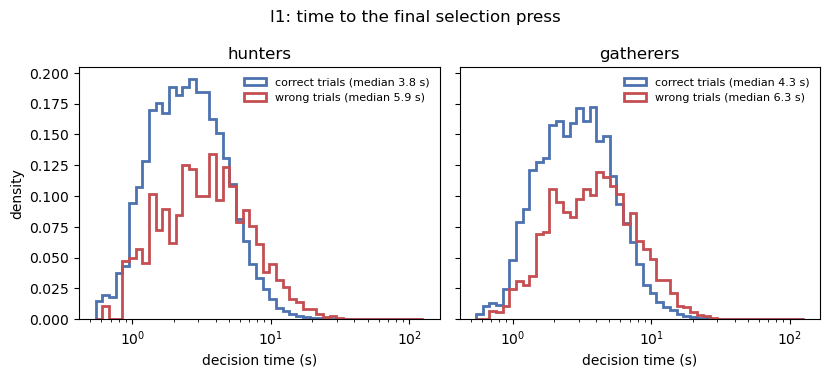

,condition,is_correct,q10,q30,q50,q70,q90,n
0,gatherers,0,2.45,4.44,6.26,8.87,13.93,1824
1,gatherers,1,1.85,3.12,4.35,5.92,9.36,7878
2,hunters,0,2.27,4.00,5.87,8.49,14.71,1269
3,hunters,1,1.60,2.68,3.78,5.21,8.32,8440


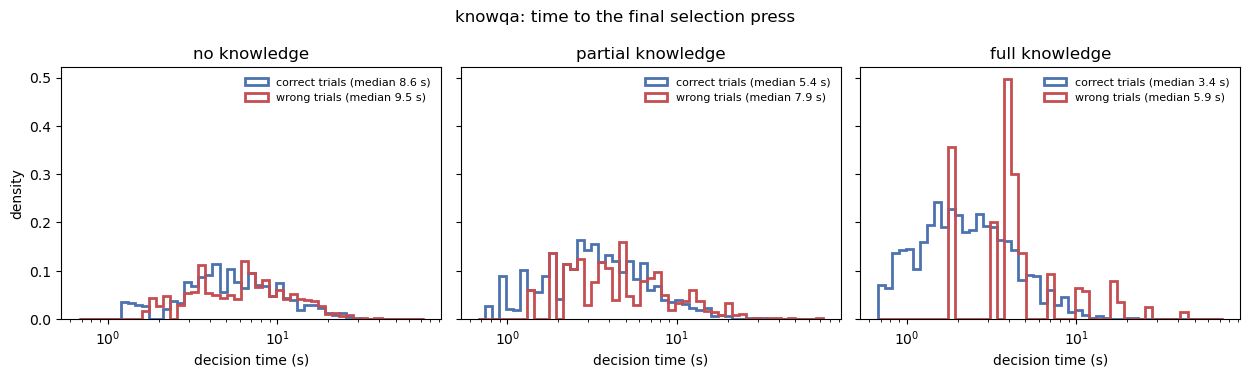

,condition,is_correct,q10,q30,q50,q70,q90,n
0,full knowledge,0,3.51,4.14,5.90,13.67,22.65,16
1,full knowledge,1,1.43,2.40,3.37,4.82,8.16,624
2,no knowledge,0,3.71,6.81,9.54,13.77,20.11,393
3,no knowledge,1,3.61,5.80,8.56,12.10,19.20,232
4,partial knowledge,0,2.81,4.88,7.86,12.69,20.42,124
5,partial knowledge,1,2.26,3.66,5.43,7.79,13.56,496


In [3]:
for key in STUDIES:
    tab = S.plot_decision_times(trials[key], dataset_key=key)
    plt.show()
    display(tab.round(2))

## 3. The gaze cascade
*`signatures.plot_gaze_cascade`*

**What is plotted.** At every moment (50 ms steps), where the eyes are, as a share of the trials
that had a fixation at that moment.

* **Left:** time from the first fixation. **Right:** time from the final selection press (the
  vertical line). **Top:** correct trials. **Bottom:** wrong trials.
* **Lines:**
  * `chosen` -- the answer the participant ends up choosing;
  * `correct, not chosen` -- the correct answer, on wrong trials only;
  * `other answer` -- the rest, per answer: their share divided by how many of them there are,
    so every line is the share of one answer and can be compared with one in four (the dotted
    line);
  * `question` -- the question.
* **Shaded bands:** one standard error across participants. Each participant's share at each
  moment is computed first, and then they are averaged, so someone with many trials does not
  count for more.

**What to look for.** The gaze cascade (Shimojo et al. 2003) is the blue line pulling away from
the others in the last seconds before the press. In the aDDM, looking at an option raises its
evidence, so the option being looked at as the evidence crosses the threshold is the one
chosen. To the right of the press is what participants look at between selecting and
confirming.

**Each moment holds only the trials still on screen then.** The far left of the right-hand
panels is the long trials only, and the far right is only trials with a slow confirm.

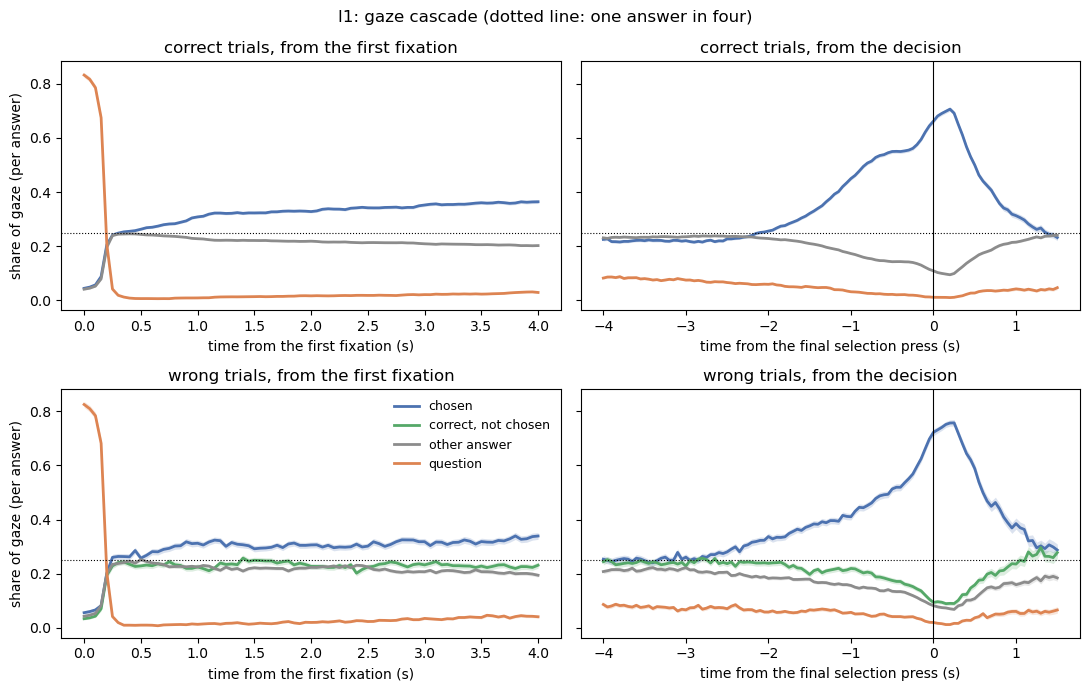

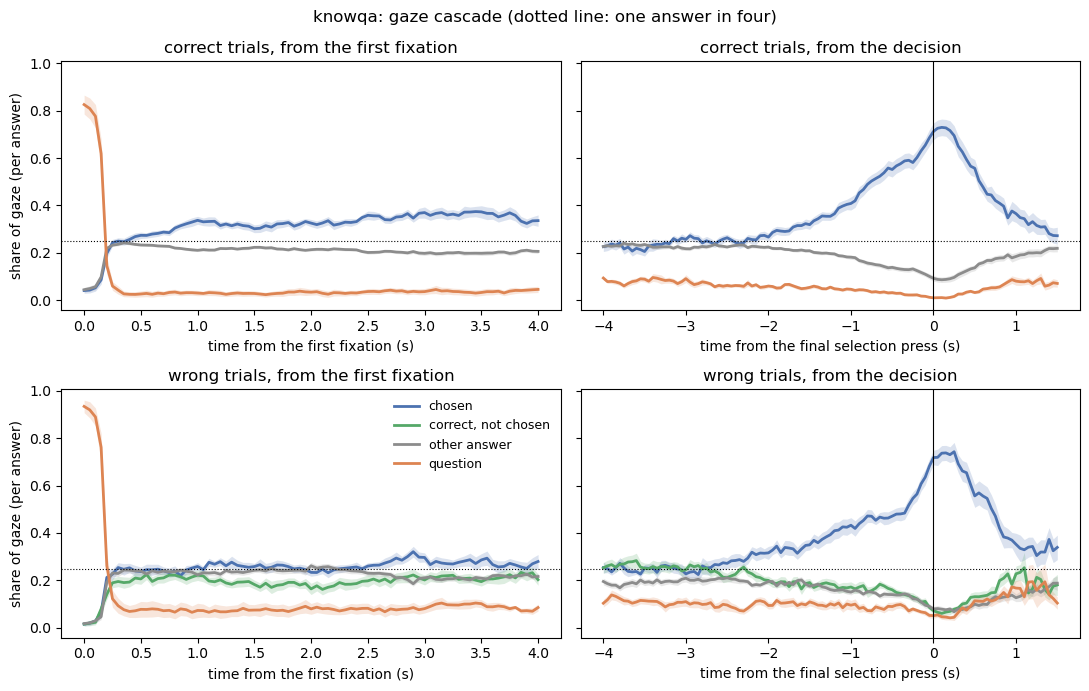

In [4]:
for key in STUDIES:
    S.plot_gaze_cascade(fix[key], trials[key], dataset_key=key)
    plt.show()

## 4. The cascade by group and by knowledge regime
*`signatures.plot_cascade_by_condition`*

The blue line from section 3 (the share of gaze on the answer about to be chosen, around the
decision), one line per hunters and gatherers on Study 1 and per knowledge regime on Study 2.

**What to compare.** Whether the cascade changes with how much the participant knows. Under no
knowledge they have no way of knowing the right answer, so the choice is close to a guess. If
the cascade is just as strong there as under full knowledge, it goes with committing to an
answer, whatever the reason for picking it.

**That does not decide between the two accounts.** Both predict a cascade for guesses too. In
the aDDM, when the options are equally good, gaze is what tips the choice. In the
post-decision account (the caveat at the top), people look at whatever they have chosen.

Wrong answers under full knowledge are few, so their line is noisy.

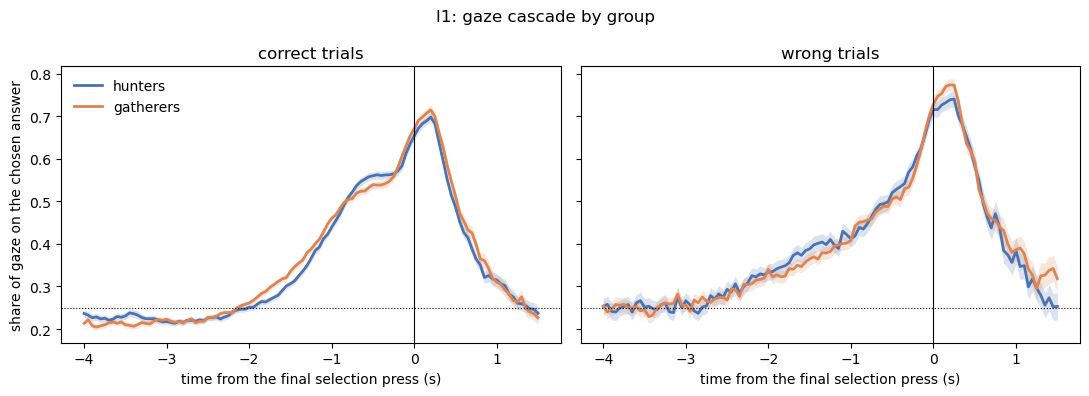

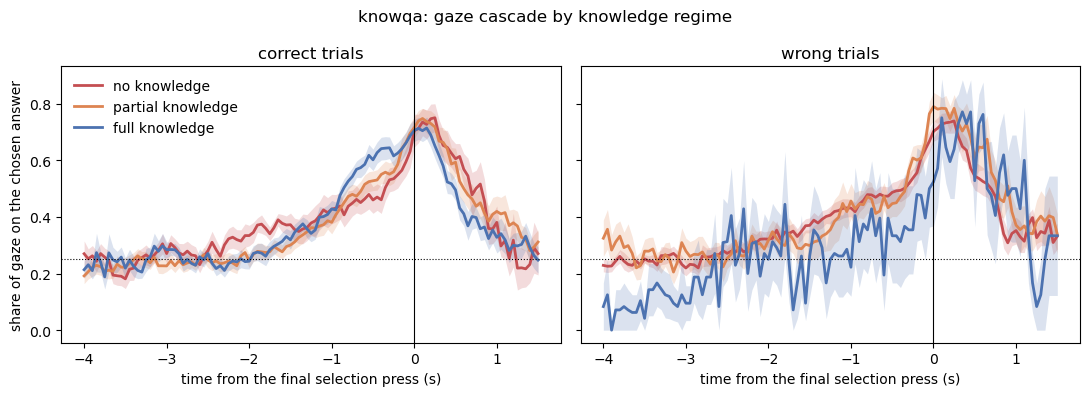

In [5]:
for key in STUDIES:
    S.plot_cascade_by_condition(fix[key], trials[key], dataset_key=key)
    plt.show()

## 5. Choice against gaze, for each kind of answer
*`signatures.plot_gaze_bias`*

**What is plotted.** Every answer on every trial is one observation:

* **x:** its share of answer gaze minus the mean share of the other three. 0 means it was looked
  at as much as an average other answer; 0.3 means 30 points more of the gaze.
* **y:** whether it was chosen.

Within each kind of answer (A to D), the answers are cut into eight bins of equal size by x, and
each dot is the choice rate in one bin. One panel per group or regime.

**How to read it.**

* **The gap between the colours** is the effect of what the answer is -- in aDDM terms, its
  value. A sits above the rest because it is correct.
* **The slope within one colour** is gaze going with choice beyond what the answer is: among
  answers of the same kind, the ones looked at more are chosen more. This is the aDDM's gaze
  bias, and what the gaze term in section 9 has to reproduce.
* **A flat line** would mean that once you know which kind of answer it is, gaze adds nothing.

**The error bars are too small.** They are binomial, over answers, and answers from one person
are alike. The dots are not averaged over participants, because one person has too few wrong
answers in a bin to give a mean of their own.

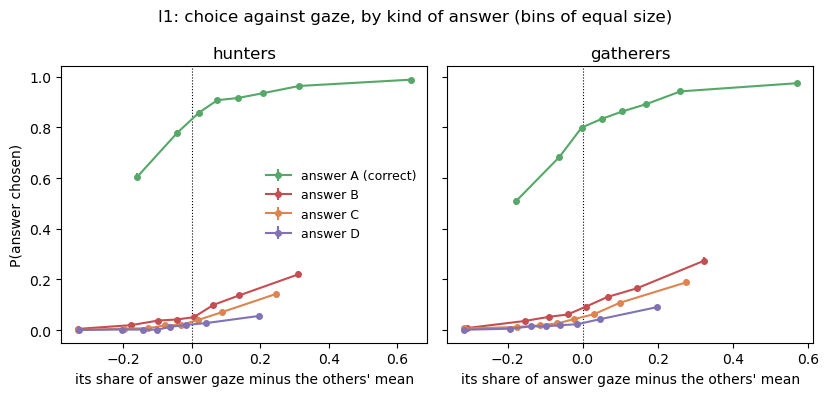

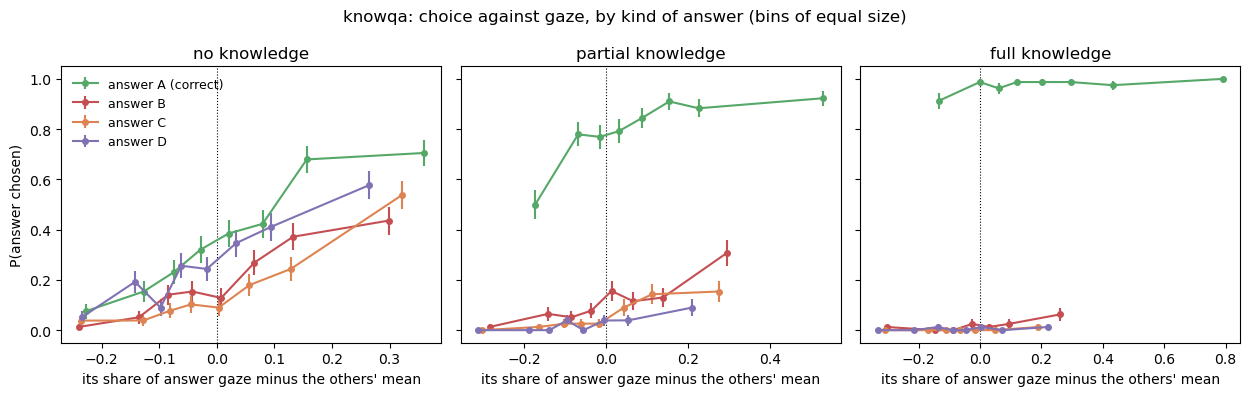

In [6]:
for key in STUDIES:
    S.plot_gaze_bias(trials[key], dataset_key=key)
    plt.show()

## 6. The first and the last answer looked at
*`signatures.plot_first_last`*

**What is plotted.** For each kind of answer:

* **grey** -- how often it is chosen at all;
* **light blue** -- how often it is chosen when it was the first answer looked at;
* **dark blue** -- how often it is chosen when it was the last answer looked at before the
  decision.

These are means over participants, with one standard error.

**What to look for.** The aDDM predicts a *last-look bias*, dark blue above grey: the option
being looked at when the evidence reaches the threshold is the one that was gaining evidence at
that moment. It predicts a weaker first-look effect, because nothing is decided that early.

The last-look bias and the cascade are the two patterns that Zylberberg et al. show can also
come from looking *after* deciding.

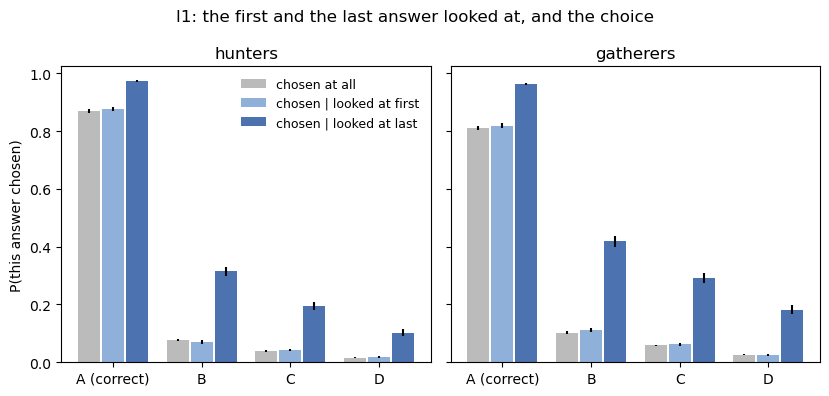

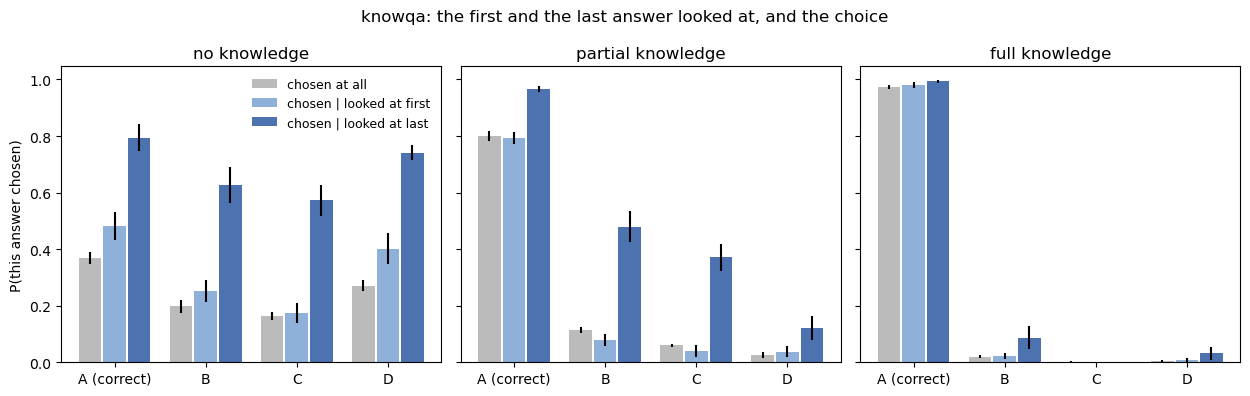

In [7]:
for key in STUDIES:
    S.plot_first_last(trials[key], dataset_key=key)
    plt.show()

## 7. How long each visit to an answer lasts
*`signatures.plot_visit_durations`*

**What is plotted.** A *visit* is a run of consecutive fixations on one answer, and its length is
the sum of those fixations, not counting the saccades between them. On every trial with at least
two answer visits before the decision, visits are labelled `first`, `last` (cut at the press),
and `middle` (everything in between). The figure shows the mean duration of each, over
participants, for correct and wrong trials.

**What to look for.** In the aDDM the last visit is cut short by the decision -- the threshold is
reached partway through it -- so it should be shorter than the middle ones. Krajbich et al.
(2010) also found first visits shorter than middle ones.

**Visits here are to whole sentences**, which take time to read, so a visit's length is partly
the answer's length. That holds equally for first, middle and last visits, so it does not
explain a difference between them.

The title says how many trials had only one answer visit and are left out: their one visit is
both the first and the last.

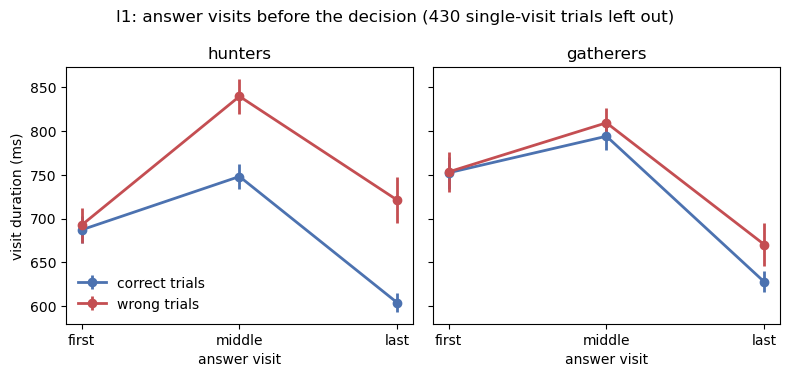

,condition,is_correct,position,mean,n_participants,n_rows,se
0,gatherers,0,first,753.3,180,1807,22.7
1,gatherers,0,last,670.3,180,1807,24.1
2,gatherers,0,middle,809.3,180,9334,16.3
3,gatherers,1,first,752.3,180,7698,18.4
4,gatherers,1,last,627.8,180,7698,12.2
5,gatherers,1,middle,794.0,180,25483,16.1
6,hunters,0,first,692.5,176,1256,19.9
7,hunters,0,last,721.0,176,1256,26.0
8,hunters,0,middle,839.5,175,6370,19.8
9,hunters,1,first,687.1,180,8220,15.5


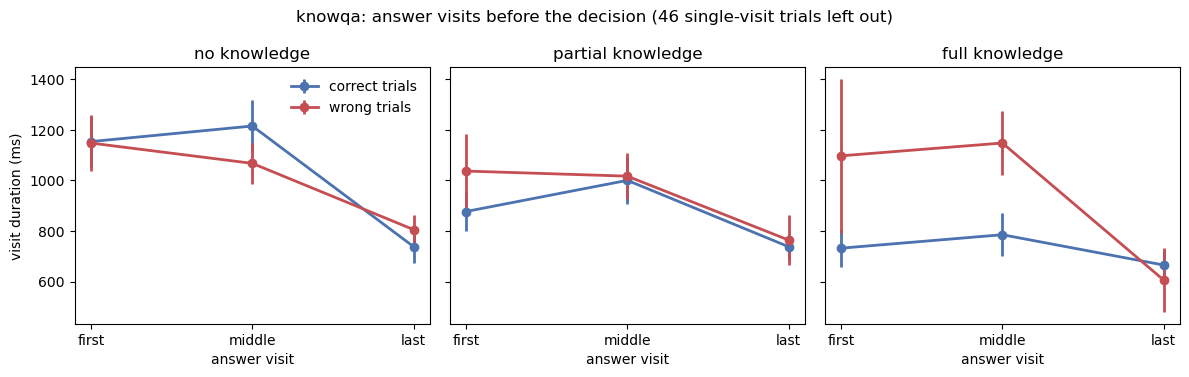

,condition,is_correct,position,mean,n_participants,n_rows,se
0,full knowledge,0,first,1096.8,8,16,303.5
1,full knowledge,0,last,605.8,8,16,126.2
2,full knowledge,0,middle,1147.4,8,95,126.8
3,full knowledge,1,first,731.9,13,596,74.5
4,full knowledge,1,last,665.3,13,596,60.1
5,full knowledge,1,middle,785.1,13,1515,84.5
6,no knowledge,0,first,1147.2,13,391,109.9
7,no knowledge,0,last,805.2,13,391,59.0
8,no knowledge,0,middle,1066.9,13,2311,80.7
9,no knowledge,1,first,1153.0,13,231,102.2


In [8]:
for key in STUDIES:
    tab = S.plot_visit_durations(fix[key], trials[key], dataset_key=key)
    plt.show()
    display(tab.round(1))

## 8. EZ-diffusion: the simplest drift-diffusion model
*`ez.fit_ez`, `ez.plot_ez`*

**The model.** Two bounds, "right" and "wrong". Evidence starts halfway between them and drifts,
with noise, until it reaches one. Three numbers describe a participant:

* `v` -- **drift rate**, how fast evidence builds up. Good comprehension means a high `v`.
* `a` -- **boundary separation**, how far apart the bounds are. A cautious participant has wide
  bounds: slower, but fewer errors.
* `Ter` -- **non-decision time**, the part of the time spent on anything else; here mostly
  reading.

**EZ** (Wagenmakers, van der Maas & Grasman 2007) gets the three directly from three numbers per
participant: their accuracy, and the mean and the variance of their correct decision times.
There is no fitting, which makes it the natural place to start. One fit per participant; on
Study 2, one per participant and regime, since everyone did all three regimes.

**What it leaves out, on purpose:** the three wrong answers are pooled into one "wrong" bound,
and the eyes play no part. It is the baseline the gaze models add to.

**Where EZ has no answer:**

* **Accuracy of exactly 1** has no finite log-odds. The method's own fix replaces it with
  1 - 1/(2n). These fits are hollow in the figure and flagged in `edge_corrected`.
* **Accuracy of exactly 0.5** gives no values at all (the printout counts them).
* **Accuracy below 0.5 gives a negative drift**, even though with four answers a participant at
  0.35 is well above chance (0.25). Under no knowledge, a negative `v` therefore means "more
  often wrong than right", not "below chance".
* **A negative `Ter`** is impossible as a time and means EZ does not describe that participant
  well.
* **The variance of the correct times is driven by the slowest trials**, and some trials take
  over a minute. Nothing is trimmed, and the fits table carries the variance so its influence
  can be seen.

**How to read the figure.** One dot per participant; on Study 2, grey lines join each person's
three regimes. The black bar is the median.

EZ: 360 fits | accuracy 1, edge-corrected: 4 | accuracy 0.5, no value: 1


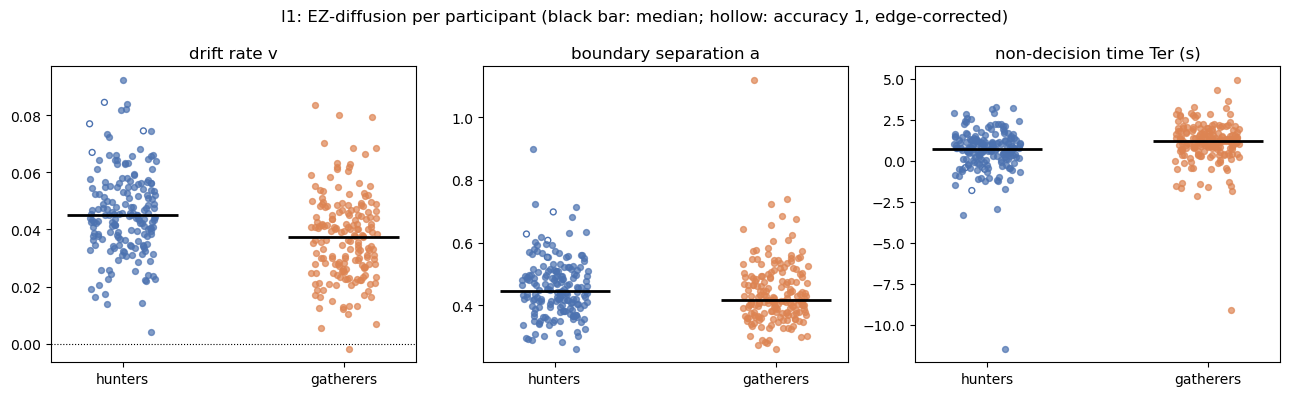

,condition,median_pc,median_v,median_a,median_Ter
0,gatherers,0.833,0.037,0.417,1.223
1,hunters,0.870,0.045,0.446,0.749


EZ: 39 fits | accuracy 1, edge-corrected: 5 | accuracy 0.5, no value: 2


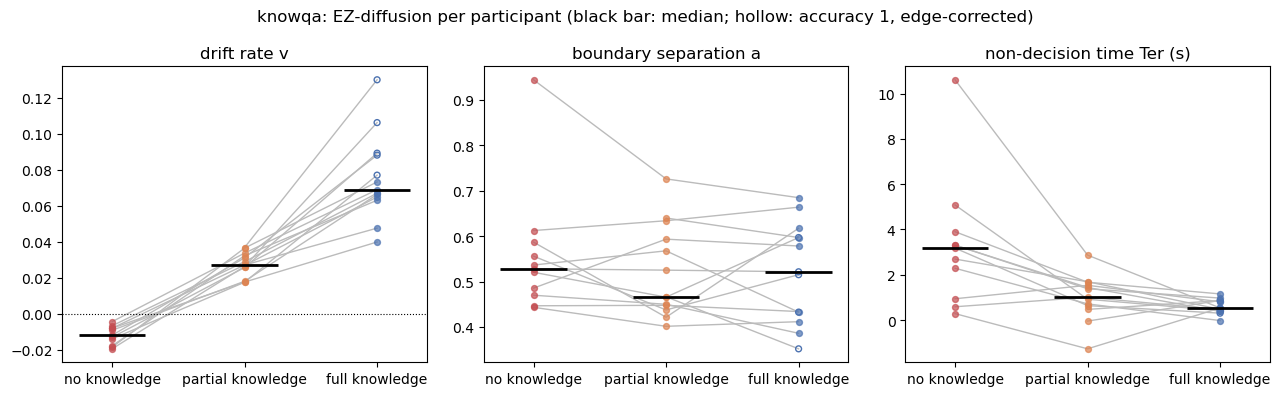

,condition,median_pc,median_v,median_a,median_Ter
0,full knowledge,0.980,0.069,0.521,0.530
1,no knowledge,0.348,-0.012,0.528,3.176
2,partial knowledge,0.820,0.027,0.466,1.006


In [9]:
ez_fits = {}
for key in STUDIES:
    ez_fits[key] = ez.fit_ez(trials[key])
    tab = ez.plot_ez(ez_fits[key], dataset_key=key)
    plt.show()
    display(tab.round(3))

## 9. GLAM: a race between the four answers, weighted by gaze
*`glam.fit_all`*

GLAM (Thomas, Molter, Krajbich, Heekeren & Mohr 2019) is the simplest model in the aDDM family
that handles more than two options and can be fitted exactly. It keeps the aDDM's main idea, that
an option gains evidence faster while it is looked at, but uses only *how much* each answer was
looked at (`gaze_A` .. `gaze_D`), not the order of the looks.

**The model, for one trial:**

1. **Each answer's evidence is its value, discounted while it is not looked at.** An answer
   looked at for a share `g` of the time gets `g * value + (1 - g) * gamma * value`. With
   `gamma = 1`, gaze makes no difference. With `gamma = 0`, an answer counts only while it is
   being looked at.
2. **What matters is how it compares with the best of the other three.** That comparison is
   squashed into a number between 0 and 1; `tau` says how sharply.
3. **Each answer has its own accumulator, rising at a speed set by step 2, with noise.** The
   first to reach the threshold is the choice, and when it gets there is the decision time.

**The parameters:**

* `v` -- overall speed of the accumulators;
* `gamma` -- the gaze discount (step 1);
* `sigma` -- noise;
* `tau` -- how sharply the answers are compared (step 2);
* `r_B`, `r_C`, `r_D` -- the value of each kind of wrong answer, with A's set to 1.

In the papers the values are ratings participants gave the items beforehand. These answers have
no rating, so the model estimates one value per kind of answer: how convincing B, C and D are,
relative to the correct answer.

**Two versions are fitted to the same trials:** with gaze (`gamma` free) and without
(`gamma = 1`, so the model predicts the same thing whatever the eyes did). The difference
between them is what gaze adds.

**One fit per group or regime**, pooling the participants, as Krajbich & Rangel (2011) did for
the aDDM. The printout flags any parameter that ends at the edge of its allowed range. Fitting
takes a few minutes on Study 1.

In [10]:
glam_fits = {}
for key in STUDIES:
    print(f"--- {key}")
    glam_fits[key] = glam.fit_all(trials[key], key)
glam_fits["knowqa"].round(3)

--- l1


  GLAM: at a bound: r_C, r_D
  hunters / gaze: v 0.21, gamma 0.428, sigma 0.262, tau 11.4, r_B 0.697, r_C 0, r_D 0, loglik -2.92e+04, aic 5.85e+04


  GLAM: at a bound: r_B, r_C, r_D
  hunters / no gaze: v 0.185, gamma 1, sigma 0.271, tau 18, r_B 0, r_C 0, r_D 0, loglik -2.96e+04, aic 5.92e+04


  GLAM: at a bound: r_D
  gatherers / gaze: v 0.175, gamma 0.351, sigma 0.248, tau 13.7, r_B 0.662, r_C 0.574, r_D 0, loglik -3.14e+04, aic 6.29e+04


  GLAM: at a bound: r_D
  gatherers / no gaze: v 0.154, gamma 1, sigma 0.258, tau 19.6, r_B 0.279, r_C 0.152, r_D 0, loglik -3.19e+04, aic 6.38e+04
--- knowqa


  GLAM: at a bound: tau
  no knowledge / gaze: v 0.0706, gamma 0.872, sigma 0.199, tau 100, r_B 0.984, r_C 0.979, r_D 0.994, loglik -2.74e+03, aic 5.49e+03


... (2 outputs left out)

  GLAM: at a bound: r_C, r_D
  partial knowledge / no gaze: v 0.109, gamma 1, sigma 0.244, tau 37.3, r_B 0.527, r_C 0, r_D 0, loglik -2.33e+03, aic 4.67e+03


  GLAM: at a bound: r_C, r_D
  full knowledge / gaze: v 0.235, gamma 0.613, sigma 0.273, tau 14.5, r_B 0.732, r_C 0, r_D 0, loglik -1.74e+03, aic 3.49e+03


  GLAM: at a bound: r_B, r_C, r_D
  full knowledge / no gaze: v 0.222, gamma 1, sigma 0.277, tau 16.9, r_B 0, r_C 0, r_D 0, loglik -1.75e+03, aic 3.5e+03


,condition,model,v,gamma,sigma,tau,r_B,r_C,r_D,loglik,n_free,n_trials,aic
0,no knowledge,gaze,0.071,0.872,0.199,100.000,0.984,0.979,0.994,-2737.872,7,625,5489.744
1,no knowledge,no gaze,0.059,1.000,0.210,3.163,0.472,0.000,0.849,-2842.470,6,625,5696.940
2,partial knowledge,gaze,0.120,0.339,0.239,14.366,0.638,0.000,0.000,-2312.180,7,620,4638.360
3,partial knowledge,no gaze,0.109,1.000,0.244,37.291,0.527,0.000,0.000,-2328.371,6,620,4668.741
4,full knowledge,gaze,0.235,0.613,0.273,14.478,0.732,0.000,0.000,-1738.396,7,640,3490.792
5,full knowledge,no gaze,0.222,1.000,0.277,16.905,0.000,0.000,0.000,-1745.814,6,640,3503.628


### 9a. The parameters
*`glam.plot_glam_parameters`*

* **Left -- `gamma`.** Below the dotted line at 1 means that gaze matters: an answer not looked
  at loses part of its value.
* **Middle -- the value of each wrong answer.** A is 1; a value of 0 means that kind of answer
  never wins on its merits.
* **Right -- how much better the gaze model fits.** This is the AIC of the model without gaze
  minus the AIC of the model with gaze. AIC rewards fit and charges for the extra parameter, so
  above about 10 is strong support for the gaze model.

**Read `gamma` together with the values.** When the three wrong answers come out about as
valuable as A (as they can under no knowledge, where nobody knows which is right), every
difference between the answers comes from gaze. Then `gamma` and `tau` trade off -- only
their combination is pinned down -- and `gamma` on its own means little; a `tau` at its upper
limit in the printout is the sign.

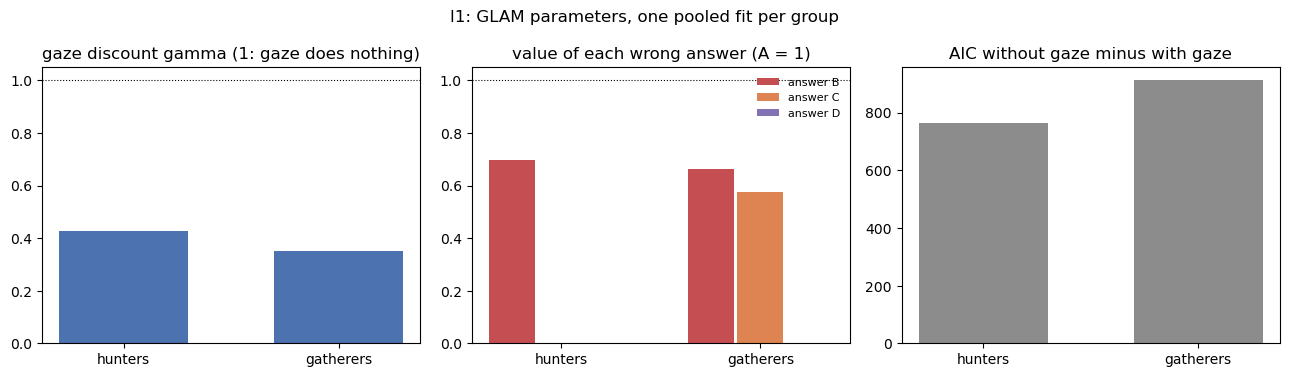

,condition,gamma,tau,r_B,r_C,r_D,loglik,aic,n_trials,aic_no_gaze_minus_gaze
0,hunters,0.428,11.444,0.697,0.000,0.0,-29225.009,58464.019,9709,762.816
1,gatherers,0.351,13.658,0.662,0.574,0.0,-31432.302,62878.604,9702,911.340


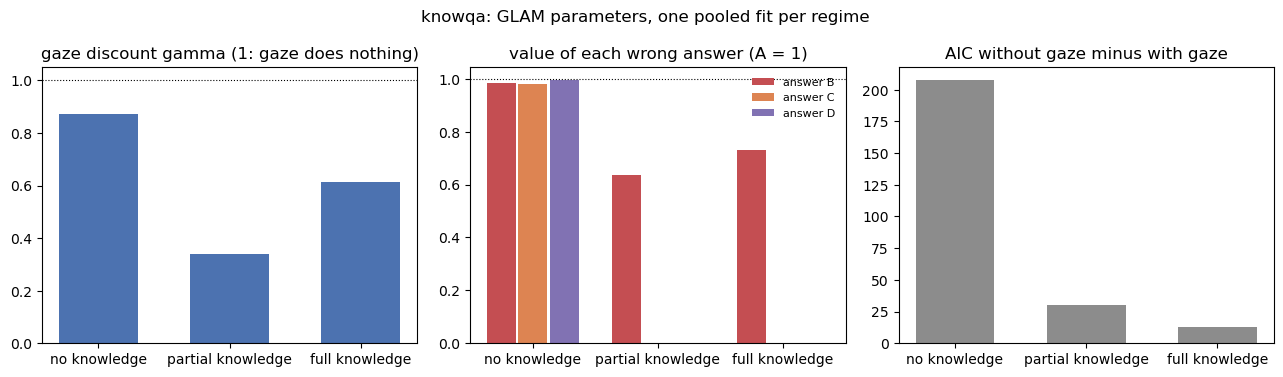

,condition,gamma,tau,r_B,r_C,r_D,loglik,aic,n_trials,aic_no_gaze_minus_gaze
0,no knowledge,0.872,100.000,0.984,0.979,0.994,-2737.872,5489.744,625,207.197
1,partial knowledge,0.339,14.366,0.638,0.000,0.000,-2312.180,4638.360,620,30.381
2,full knowledge,0.613,14.478,0.732,0.000,0.000,-1738.396,3490.792,640,12.836


In [11]:
for key in STUDIES:
    tab = glam.plot_glam_parameters(glam_fits[key], dataset_key=key)
    plt.show()
    display(tab.round(3))

### 9b. The models against the data
*`glam.plot_glam_check`*

Each fitted model is run 20 times on every trial, each time with that trial's own gaze shares,
and the simulated choices and times are compared with the real ones.

* **Top row:** the dots are the data from section 5, and the lines are each model's prediction
  for the same answers. Solid is the gaze model and dashed is the model without gaze. The dashed
  lines are flat by construction, since that model ignores the eyes. A good gaze model follows
  the slopes of the dots.
* **Bottom row:** the decision-time percentiles (10, 30, 50, 70 and 90%), model against data,
  for correct (blue) and wrong (red) answers. Points on the dotted diagonal would be a perfect
  fit.

**Where this simple version falls short, and why:**

* **Pooling participants.** People differ a lot in speed. One pooled model needs a lot of noise
  to cover them all, and the noise makes wrong answers win too often and too early.
* **Gaze can only help an answer with value.** In GLAM gaze multiplies value, so an answer the
  model values at 0 gains nothing from being looked at, even where the data show it is chosen
  more when looked at more.
* **No non-decision time.** The whole time to the press, reading included, has to come from the
  race itself.

The models are fitted and checked on the same trials.

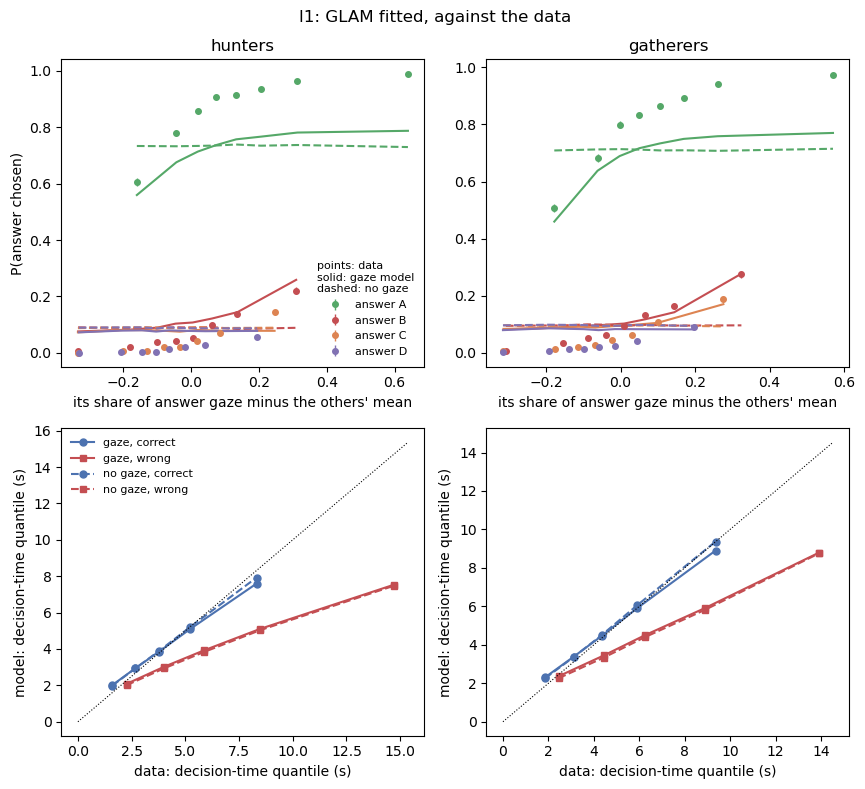

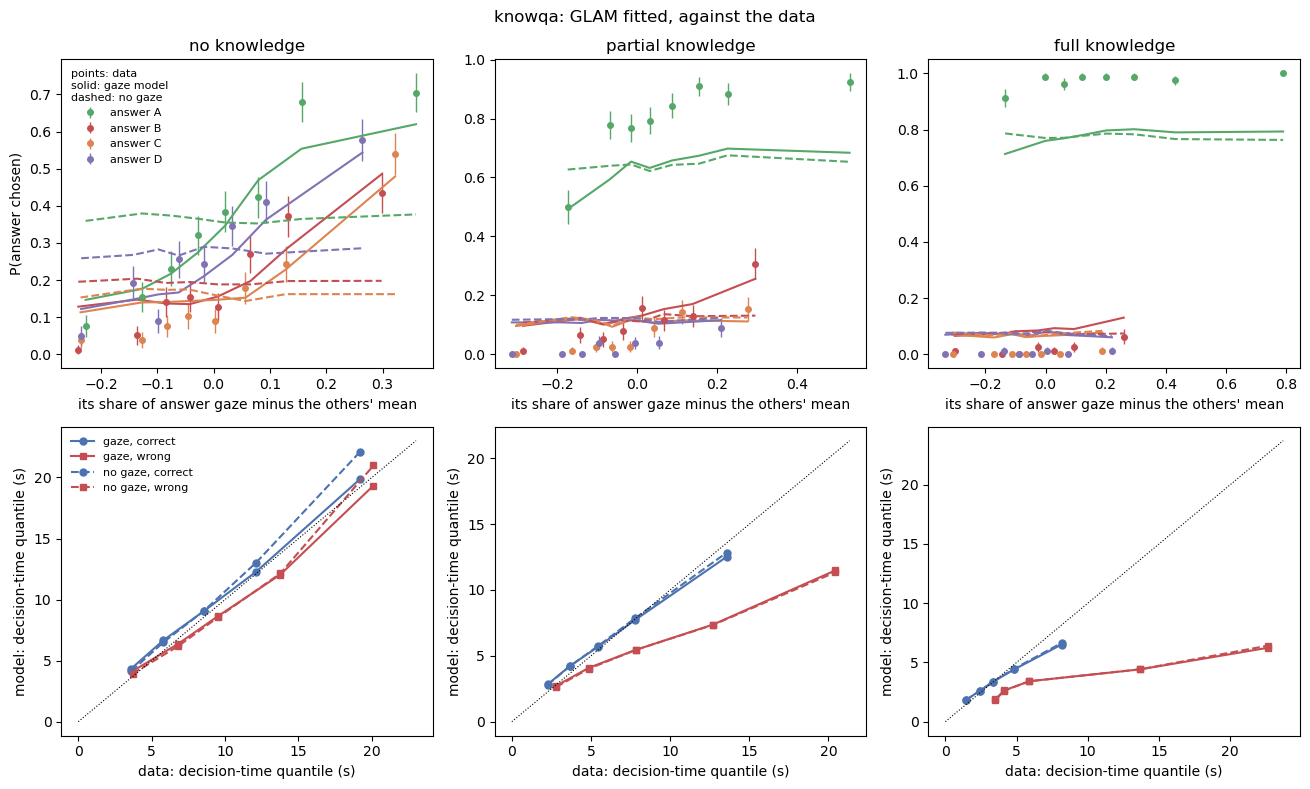

In [12]:
for key in STUDIES:
    glam.plot_glam_check(trials[key], glam_fits[key], dataset_key=key)
    plt.show()

## Not in this notebook

* **GLAM fitted per participant**, as in the GLAM paper. Each person gets their own `gamma` --
  how much their choices follow their eyes -- and fitting per person addresses the pooling
  problem in 9b.
* **The full aDDM** (Krajbich et al. 2010; Krajbich & Rangel 2011), which uses the order and
  length of each look rather than the overall shares. It has no exact likelihood and is fitted
  by simulating fixation sequences.